# 🎓 DropGuard: Early Warning Student Dropout System
### **Interactive Lab: Preprocessing, Train/Test Split & Model Training**
---
**Team:** Member 1 (ML & Data Engineering Lead)  
**Dataset:** UCI Repository #697 — *Predict Students' Dropout and Academic Success* (4,424 College Students, 36 Attributes)

### 🔹 **Cell 1: Import Required Libraries**

In [13]:
# Cell 1: Import Libraries
import os
import io
import zipfile
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

print("[Cell 1 ✔] All libraries imported successfully!")

[Cell 1 ✔] All libraries imported successfully!


### 🔹 **Cell 2: Load Dataset (Works in Google Colab AND Local Windows)**
Loads the raw dataset and sanitizes column names.

In [14]:
# Cell 2: Load Dataset
LOCAL_WIN_PATH = r"C:\Users\hp\OneDrive\Desktop\Supervised\data\student_data.csv"

if os.path.exists(LOCAL_WIN_PATH):
    RAW_CSV_PATH = LOCAL_WIN_PATH
    PREPROCESSED_CSV_PATH = r"C:\Users\hp\OneDrive\Desktop\Supervised\data\preprocessed_student_data.csv"
elif os.path.exists("data/student_data.csv"):
    RAW_CSV_PATH = "data/student_data.csv"
    PREPROCESSED_CSV_PATH = "data/preprocessed_student_data.csv"
elif os.path.exists("../data/student_data.csv"):
    RAW_CSV_PATH = "../data/student_data.csv"
    PREPROCESSED_CSV_PATH = "../data/preprocessed_student_data.csv"
else:
    print("[*] Remote environment detected. Downloading dataset directly from UCI...")
    UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
    req = urllib.request.Request(UCI_ZIP_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as response:
        with zipfile.ZipFile(io.BytesIO(response.read())) as z:
            csv_filename = next(f for f in z.namelist() if f.endswith(".csv"))
            with z.open(csv_filename) as f:
                temp_df = pd.read_csv(f, sep=";")
                if len(temp_df.columns) <= 1:
                    f.seek(0)
                    temp_df = pd.read_csv(f, sep=",")
                temp_df.to_csv("student_data.csv", index=False)
    RAW_CSV_PATH = "student_data.csv"
    PREPROCESSED_CSV_PATH = "preprocessed_student_data.csv"

df = pd.read_csv(RAW_CSV_PATH)
df.columns = [c.strip() for c in df.columns]

print(f"[Cell 2 ✔] Loaded {len(df)} total students with {len(df.columns)} attributes.")
df.head(3)

[*] Remote environment detected. Downloading dataset directly from UCI...
[Cell 2 ✔] Loaded 4424 total students with 37 attributes.


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout


### 🔹 **Cell 3: Target Formulation (Binary Early Warning)**
Filters dataset for **Dropout ($Y=1$) vs. Graduate ($Y=0$)**.

In [15]:
# Cell 3: Target Variable Formulation
binary_df = df[df['Target'].isin(['Dropout', 'Graduate'])].copy()
binary_df['is_dropout'] = (binary_df['Target'] == 'Dropout').astype(int)

print(f"[Cell 3 ✔] Filtered binary dataset: {len(binary_df)} students")
print(f"    - At-Risk Dropouts (Class 1): {binary_df['is_dropout'].sum()}")
print(f"    - Successful Graduates (Class 0): {len(binary_df) - binary_df['is_dropout'].sum()}")

[Cell 3 ✔] Filtered binary dataset: 3630 students
    - At-Risk Dropouts (Class 1): 1421
    - Successful Graduates (Class 0): 2209


### 🔹 **Cell 4: TRAIN / TEST SPLIT (80% Training, 20% Holdout Testing)**
**Here is where the dataset is split before any transformations are applied!**  
We use `stratify=y` so both the training and test sets have the exact same proportion of dropouts.

In [16]:
# Cell 4: DEDICATED TRAIN / TEST SPLIT
X = binary_df.drop(columns=['Target', 'is_dropout'])
y = binary_df['is_dropout']

# 80% Train, 20% Test (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print("=" * 65)
print("                   TRAIN / TEST SPLIT SUMMARY")
print("=" * 65)
print(f"Total Students Available : {len(X)}")
print(f"Training Set (80%)       : {X_train.shape[0]} students")
print(f"  ↳ Training Dropouts    : {y_train.sum()} ({y_train.mean()*100:.1f}%)")
print(f"  ↳ Training Graduates   : {len(y_train) - y_train.sum()} ({(1 - y_train.mean())*100:.1f}%)")
print("-" * 65)
print(f"Test Set (20%)           : {X_test.shape[0]} students (Unseen Holdout)")
print(f"  ↳ Test Dropouts        : {y_test.sum()} ({y_test.mean()*100:.1f}%)")
print(f"  ↳ Test Graduates       : {len(y_test) - y_test.sum()} ({(1 - y_test.mean())*100:.1f}%)")
print("=" * 65)
print("[Cell 4 ✔] Train/Test Split successfully completed!")

                   TRAIN / TEST SPLIT SUMMARY
Total Students Available : 3630
Training Set (80%)       : 2904 students
  ↳ Training Dropouts    : 1137 (39.2%)
  ↳ Training Graduates   : 1767 (60.8%)
-----------------------------------------------------------------
Test Set (20%)           : 726 students (Unseen Holdout)
  ↳ Test Dropouts        : 284 (39.1%)
  ↳ Test Graduates       : 442 (60.9%)
[Cell 4 ✔] Train/Test Split successfully completed!


### 🔹 **Cell 5: Feature Preprocessing (`ColumnTransformer`)**
We fit `StandardScaler` and `OneHotEncoder` **strictly on `X_train`** to prevent data leakage.

In [17]:
# Cell 5: Preprocessing Transformation
NUMERICAL_FEATURES = [
    'Previous qualification (grade)', 'Admission grade', 'Age at enrollment',
    'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)',
    'Unemployment rate', 'Inflation rate', 'GDP'
]

CATEGORICAL_FEATURES = [
    'Marital status', 'Application mode', 'Application order', 'Course',
    'Previous qualification', 'Nacionality', "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation"
]

BINARY_FEATURES = [
    'Daytime/evening attendance', 'Displaced', 'Educational special needs',
    'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International'
]

# Build Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), NUMERICAL_FEATURES),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
        ('bin', 'passthrough', BINARY_FEATURES)
    ]
)

# Fit on X_train only and transform both
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

# Feature names
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_names = cat_encoder.get_feature_names_out(CATEGORICAL_FEATURES).tolist()
all_feature_names = NUMERICAL_FEATURES + encoded_cat_names + BINARY_FEATURES

print(f"[Cell 5 ✔] Preprocessing complete! {X_train.shape[1]} raw columns -> {X_train_proc.shape[1]} encoded features.")

[Cell 5 ✔] Preprocessing complete! 36 raw columns -> 232 encoded features.


### 🔹 **Cell 6: Save Preprocessed Dataset Directly to CSV (End of Preprocessing)**
Exports the clean preprocessed training data directly to CSV.

In [18]:
# Cell 6: Export Preprocessed CSV
processed_df = pd.DataFrame(X_train_proc, columns=all_feature_names)
processed_df['Target_is_dropout'] = y_train.values

processed_df.to_csv(PREPROCESSED_CSV_PATH, index=False)

print("=" * 70)
print(f"[Cell 6 ✔] PREPROCESSED DATA SAVED TO: {PREPROCESSED_CSV_PATH}")
print(f"           Shape: {processed_df.shape} (Rows: {processed_df.shape[0]}, Columns: {processed_df.shape[1]})")
print("=" * 70)
print("🏁 PREPROCESSING IS 100% COMPLETE!")
processed_df.head(2)

[Cell 6 ✔] PREPROCESSED DATA SAVED TO: preprocessed_student_data.csv
           Shape: (2904, 233) (Rows: 2904, Columns: 233)
🏁 PREPROCESSING IS 100% COMPLETE!


,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),...,Father's occupation_194,Daytime/evening attendance,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,International,Target_is_dropout
0,0.537140,0.529812,4.782557,-0.304182,-0.523942,-1.888,-1.502236,-2.11295,-0.189776,-0.28645,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1
1,-0.970016,-0.855959,-0.570564,-0.304182,-0.134007,-1.888,-1.502236,-2.11295,-0.189776,-0.28645,...,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1


---
# 🚀 **PART 2: MODEL TRAINING BEGINS HERE**
### 🔹 **Cell 7: Train Random Forest on Preprocessed Features**

In [19]:
# Cell 7: Model Training & Evaluation
print("[*] Training Random Forest on preprocessed features...")
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=14,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# THE EXACT TRAINING MOMENT
rf_model.fit(X_train_proc, y_train)

# Evaluate on Holdout Test Set
y_pred = rf_model.predict(X_test_proc)
y_prob = rf_model.predict_proba(X_test_proc)[:, 1]

print("\n" + "=" * 50)
print("          MODEL PERFORMANCE EVALUATION")
print("=" * 50)
print(classification_report(y_test, y_pred, target_names=['Graduate', 'Dropout']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
print("=" * 50)

[*] Training Random Forest on preprocessed features...

          MODEL PERFORMANCE EVALUATION
              precision    recall  f1-score   support

    Graduate       0.92      0.96      0.94       442
     Dropout       0.93      0.87      0.90       284

    accuracy                           0.92       726
   macro avg       0.93      0.91      0.92       726
weighted avg       0.92      0.92      0.92       726

ROC-AUC Score: 0.9706


### 🔹 **Cell 8: Top Risk Drivers (Feature Importance Plot)**

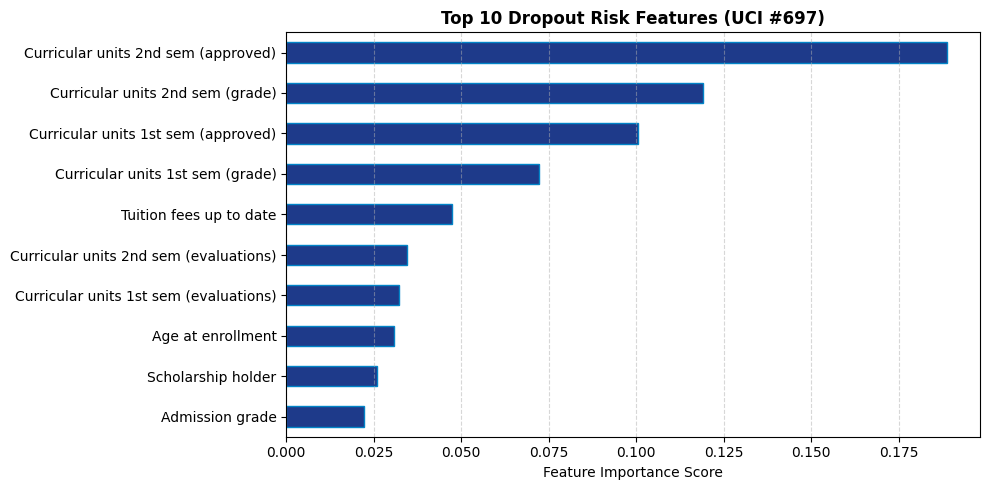

[Cell 8 ✔] All steps finished successfully!


In [20]:
# Cell 8: Top 10 Feature Importance Plot
importances = pd.Series(rf_model.feature_importances_, index=all_feature_names).sort_values(ascending=True)

plt.figure(figsize=(10, 5))
importances.tail(10).plot(kind='barh', color='#1E3A8A', edgecolor='#0284C7')
plt.title('Top 10 Dropout Risk Features (UCI #697)', fontweight='bold')
plt.xlabel('Feature Importance Score')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
print("[Cell 8 ✔] All steps finished successfully!")